# Zajęcia 2 — Sieci rekurencyjne: budowa i uczenie

**Cel:** zaimplementować prosty RNN w PyTorch i nauczyć go przewidywać kolejną
próbkę szeregu czasowego (sygnał sinusoidalny z szumem). Zbadać krzywą uczenia
oraz wpływ typu komórki (RNN/LSTM/GRU), liczby jednostek i długości okna.

Uruchamiaj komórki po kolei (Shift+Enter).

*Prowadzący: dr Tomasz Cieplak / mgr inż. Patryk Marek, Rok akademicki: 2026/27*

## 1. Instalacja i import

In [1]:
!pip -q install torch numpy matplotlib


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


In [2]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

torch.manual_seed(0); np.random.seed(0)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Urządzenie:', DEVICE)

Urządzenie: cpu


## 2. Dane: szereg czasowy

Generujemy sygnał sinusoidalny z niewielkim szumem — prosty, powtarzalny szereg,
na którym łatwo zobaczyć, czy sieć nauczyła się struktury.

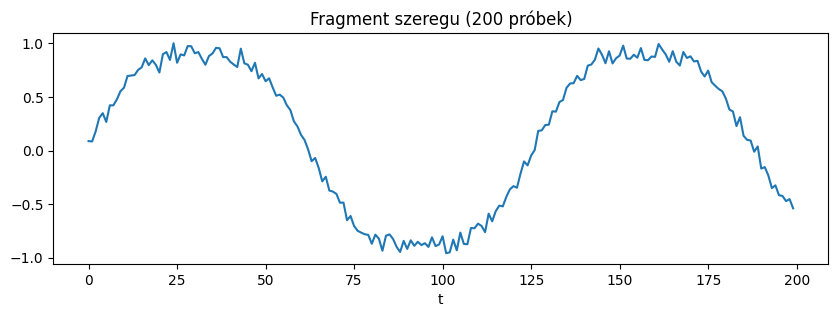

In [3]:
def generuj_szereg(n=2000):
    t = np.linspace(0, 100, n)
    y = np.sin(t) + 0.1*np.sin(3*t) + 0.05*np.random.randn(n)
    return y.astype(np.float32)

seria = generuj_szereg()
plt.figure(figsize=(10,3))
plt.plot(seria[:200])
plt.title('Fragment szeregu (200 próbek)'); plt.xlabel('t'); plt.show()

## 3. Okna wejście–cel

Z ciągu tworzymy przykłady uczące: **okno** kolejnych próbek jako wejście,
a następna próbka jako cel (zadanie *sequence-to-vector*).

In [4]:
def zrob_okna(seria, okno=30):
    X, Y = [], []
    for i in range(len(seria)-okno):
        X.append(seria[i:i+okno]); Y.append(seria[i+okno])
    X = np.array(X, dtype=np.float32)[..., None]  # [N, okno, 1]
    Y = np.array(Y, dtype=np.float32)[:, None]     # [N, 1]
    return X, Y

OKNO = 30
X, Y = zrob_okna(seria, OKNO)

# Podział chronologiczny (bez tasowania — to szereg czasowy!)
n_tr = int(0.8*len(X))
Xtr = torch.tensor(X[:n_tr]).to(DEVICE); Ytr = torch.tensor(Y[:n_tr]).to(DEVICE)
Xte = torch.tensor(X[n_tr:]).to(DEVICE); Yte = torch.tensor(Y[n_tr:]).to(DEVICE)
print('Trening:', Xtr.shape, ' Test:', Xte.shape)

Trening: torch.Size([1576, 30, 1])  Test: torch.Size([394, 30, 1])


## 4. Model RNN

Jedna warstwa rekurencyjna + warstwa liniowa na ostatnim stanie ukrytym.
Parametr `typ` przełącza SimpleRNN / LSTM / GRU.

In [5]:
class ModelRNN(nn.Module):
    def __init__(self, hidden=32, typ='RNN'):
        super().__init__()
        rnn = {'RNN': nn.RNN, 'LSTM': nn.LSTM, 'GRU': nn.GRU}[typ]
        self.rnn = rnn(input_size=1, hidden_size=hidden, batch_first=True)
        self.fc = nn.Linear(hidden, 1)
    def forward(self, x):
        out, _ = self.rnn(x)
        return self.fc(out[:, -1, :])   # ostatni krok -> predykcja

## 5. Pętla uczenia

In [6]:
def trenuj(model, Xtr, Ytr, Xte, Yte, epoki=30, lr=1e-2, batch=64):
    model = model.to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    strata = nn.MSELoss()
    hist = []
    hist_tr = [] 
    n = len(Xtr)
    for ep in range(epoki):
        model.train()
        perm = torch.randperm(n)
        for i in range(0, n, batch):
            idx = perm[i:i+batch]
            opt.zero_grad()
            loss = strata(model(Xtr[idx]), Ytr[idx])
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)  
            opt.step()
        model.eval()
        with torch.no_grad():
            hist_tr.append(strata(model(Xtr), Ytr).item()) 
            hist.append(strata(model(Xte), Yte).item())    
    return hist, hist_tr

heurystyka_mse = ((Yte - Xte[:, -1])**2).mean().item()
print(f"MSE heurystyki 'ostatnia próbka': {heurystyka_mse:.5f}")

model = ModelRNN(hidden=32, typ='RNN')
hist, hist_tr = trenuj(model, Xtr, Ytr, Xte, Yte, epoki=30)
print(f'Strata test: {hist[0]:.4f} -> {hist[-1]:.4f}')

MSE heurystyki 'ostatnia próbka': 0.00631
Strata test: 0.0078 -> 0.0038


## 6. Krzywa uczenia

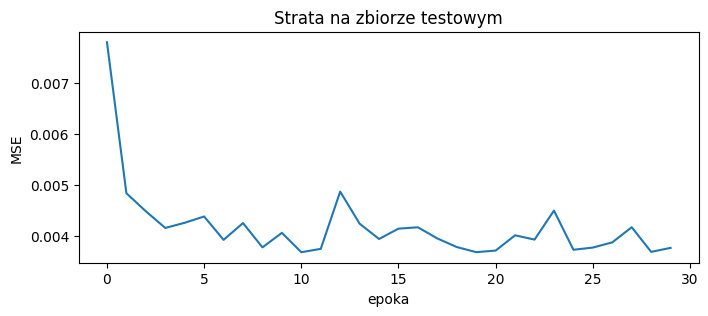

In [7]:
plt.figure(figsize=(8,3))
plt.plot(hist)
plt.title('Strata na zbiorze testowym'); plt.xlabel('epoka'); plt.ylabel('MSE'); plt.show()

## 7. Predykcja vs rzeczywistość

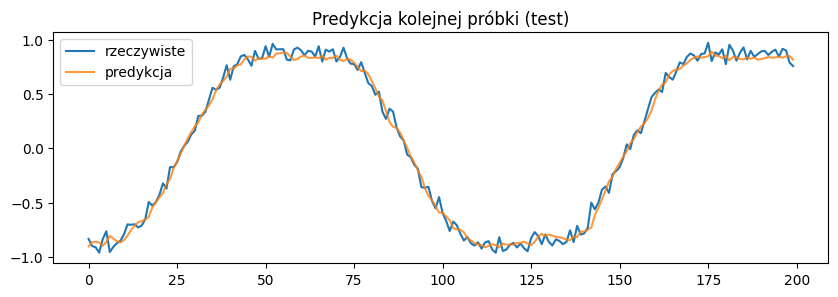

In [8]:
model.eval()
with torch.no_grad():
    pred = model(Xte).cpu().numpy().ravel()
prawdziwe = Yte.cpu().numpy().ravel()

plt.figure(figsize=(10,3))
plt.plot(prawdziwe[:200], label='rzeczywiste')
plt.plot(pred[:200], label='predykcja', alpha=0.8)
plt.legend(); plt.title('Predykcja kolejnej próbki (test)'); plt.show()

## 8. Eksperyment: typ komórki oraz liczba jednostek

Porównanie SimpleRNN/LSTM/GRU i wpływu rozmiaru stanu ukrytego.

In [9]:
print('Typ komórki (hidden=32):')
for typ in ['RNN','LSTM','GRU']:
    h, h_tr = trenuj(ModelRNN(hidden=32, typ=typ), Xtr, Ytr, Xte, Yte, epoki=20)
    print(f'  {typ:5s} test MSE = {h[-1]:.4f}')

print('Liczba jednostek (GRU):')
for hs in [8, 32, 64]:
    h, h_tr = trenuj(ModelRNN(hidden=hs, typ='GRU'), Xtr, Ytr, Xte, Yte, epoki=20)
    print(f'  hidden={hs:3d} test MSE = {h[-1]:.4f}')

Typ komórki (hidden=32):
  RNN   test MSE = 0.0055
  LSTM  test MSE = 0.0036
  GRU   test MSE = 0.0035
Liczba jednostek (GRU):
  hidden=  8 test MSE = 0.0034
  hidden= 32 test MSE = 0.0038
  hidden= 64 test MSE = 0.0034


Config: GRU, hidden= 8 | Parametry:   273 | MSE: 0.00380 ± 0.00004 | Czas: 1.08 s
Config: GRU, hidden=16 | Parametry:   929 | MSE: 0.00374 ± 0.00002 | Czas: 1.20 s
Config: GRU, hidden=32 | Parametry:  3393 | MSE: 0.00376 ± 0.00001 | Czas: 1.53 s
Config: GRU, hidden=64 | Parametry: 12929 | MSE: 0.00375 ± 0.00008 | Czas: 2.35 s


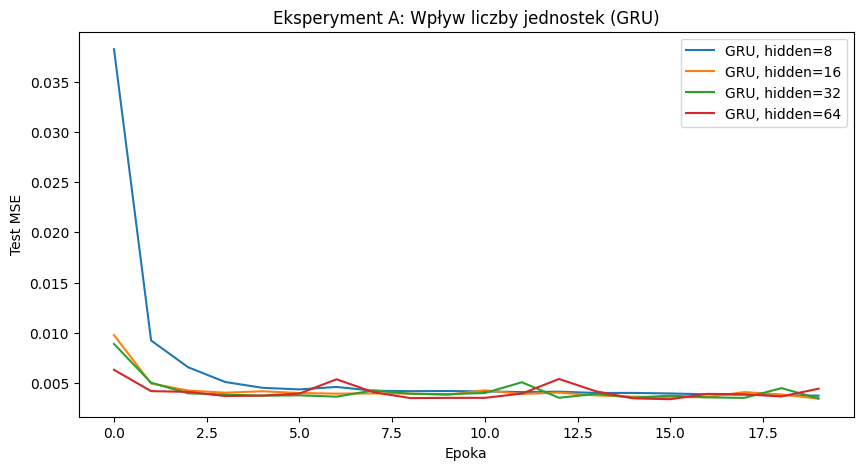

In [10]:
import time
import numpy as np

badane_hidden = [8, 16, 32, 64]
typ_komorki = 'GRU'

plt.figure(figsize=(10,5))

for hs in badane_hidden:
    wyniki, czasy = [], []
    hist_do_wykresu = []
    
    for seed in [0, 1, 2]:
        torch.manual_seed(seed)
        model = ModelRNN(hidden=hs, typ=typ_komorki)
        
        t0 = time.perf_counter()
        h, h_tr = trenuj(model, Xtr, Ytr, Xte, Yte, epoki=20, lr=1e-2, batch=64)
        czasy.append(time.perf_counter() - t0)
        
        wyniki.append(np.mean(h[-5:]))
        if seed == 0: 
            hist_do_wykresu = h
            
    plt.plot(hist_do_wykresu, label=f'GRU, hidden={hs}')
    
    parametry = sum(p.numel() for p in model.parameters())
    srednie_mse = np.mean(wyniki)
    odchylenie_mse = np.std(wyniki)
    sredni_czas = np.mean(czasy)
    
    print(f'Config: {typ_komorki}, hidden={hs:2d} | Parametry: {parametry:5d} | '
          f'MSE: {srednie_mse:.5f} ± {odchylenie_mse:.5f} | Czas: {sredni_czas:.2f} s')

plt.title(f'Eksperyment A: Wpływ liczby jednostek ({typ_komorki})')
plt.xlabel('Epoka')
plt.ylabel('Test MSE')
plt.legend()
plt.show()

Config: GRU, OKNO= 10 | Parametry:  3393 | MSE: 0.00414 ± 0.00019 | Czas: 0.65 s
Config: GRU, OKNO= 30 | Parametry:  3393 | MSE: 0.00376 ± 0.00001 | Czas: 1.62 s
Config: GRU, OKNO= 60 | Parametry:  3393 | MSE: 0.00343 ± 0.00021 | Czas: 3.08 s
Config: GRU, OKNO=120 | Parametry:  3393 | MSE: 0.00344 ± 0.00019 | Czas: 5.85 s


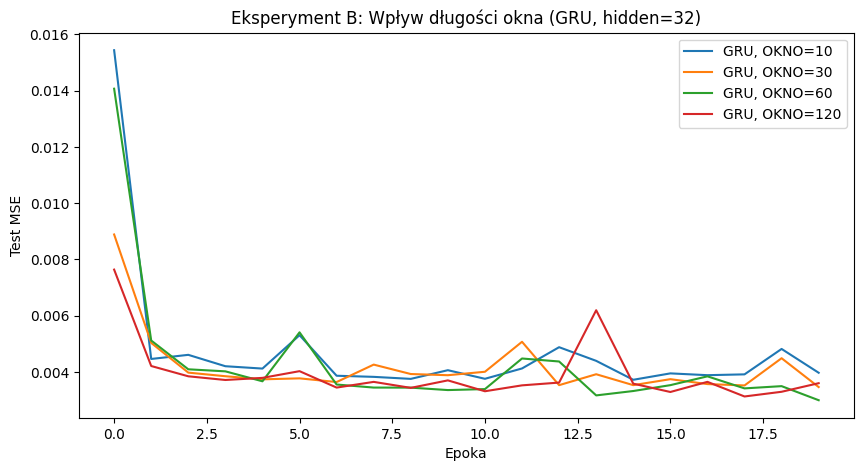

In [11]:
import time
import numpy as np

badane_okno = [10, 30, 60, 120]
typ_komorki = 'GRU'
hs = 32

plt.figure(figsize=(10,5))

for o in badane_okno:
    wyniki, czasy = [], []
    hist_do_wykresu = []
    
    X, Y = zrob_okna(seria, o)
    n_tr = int(0.8*len(X))
    Xtr = torch.tensor(X[:n_tr]).to(DEVICE)
    Ytr = torch.tensor(Y[:n_tr]).to(DEVICE)
    Xte = torch.tensor(X[n_tr:]).to(DEVICE)
    Yte = torch.tensor(Y[n_tr:]).to(DEVICE)
    
    for seed in [0, 1, 2]:
        torch.manual_seed(seed)
        model = ModelRNN(hidden=hs, typ=typ_komorki)
        
        t0 = time.perf_counter()
        h, h_tr = trenuj(model, Xtr, Ytr, Xte, Yte, epoki=20, lr=1e-2, batch=64)
        czasy.append(time.perf_counter() - t0)
        
        wyniki.append(np.mean(h[-5:]))
        if seed == 0: 
            hist_do_wykresu = h
            
    plt.plot(hist_do_wykresu, label=f'GRU, OKNO={o}')
    
    parametry = sum(p.numel() for p in model.parameters())
    srednie_mse = np.mean(wyniki)
    odchylenie_mse = np.std(wyniki)
    sredni_czas = np.mean(czasy)
    
    print(f'Config: {typ_komorki}, OKNO={o:3d} | Parametry: {parametry:5d} | '
          f'MSE: {srednie_mse:.5f} ± {odchylenie_mse:.5f} | Czas: {sredni_czas:.2f} s')

plt.title(f'Eksperyment B: Wpływ długości okna ({typ_komorki}, hidden={hs})')
plt.xlabel('Epoka')
plt.ylabel('Test MSE')
plt.legend()
plt.show()

Config: RNN , OKNO= 10 | Parametry:  1153 | MSE: 0.00417 ± 0.00025 | Czas: 0.32 s
Config: LSTM, OKNO= 10 | Parametry:  4513 | MSE: 0.00415 ± 0.00011 | Czas: 0.65 s
Config: GRU , OKNO= 10 | Parametry:  3393 | MSE: 0.00414 ± 0.00019 | Czas: 0.59 s
Config: RNN , OKNO=120 | Parametry:  1153 | MSE: 0.00400 ± 0.00001 | Czas: 2.37 s
Config: LSTM, OKNO=120 | Parametry:  4513 | MSE: 0.00375 ± 0.00013 | Czas: 6.51 s
Config: GRU , OKNO=120 | Parametry:  3393 | MSE: 0.00344 ± 0.00019 | Czas: 5.86 s


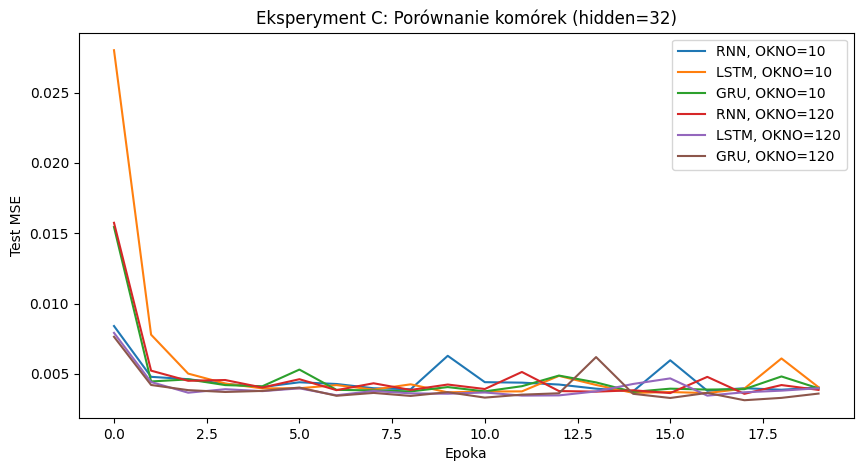

In [12]:
import time
import numpy as np

badane_okna = [10, 120]
typy_komorek = ['RNN', 'LSTM', 'GRU']
hs = 32

plt.figure(figsize=(10,5))

for o in badane_okna:
    X, Y = zrob_okna(seria, o)
    n_tr = int(0.8*len(X))
    Xtr = torch.tensor(X[:n_tr]).to(DEVICE)
    Ytr = torch.tensor(Y[:n_tr]).to(DEVICE)
    Xte = torch.tensor(X[n_tr:]).to(DEVICE)
    Yte = torch.tensor(Y[n_tr:]).to(DEVICE)
    
    for typ in typy_komorek:
        wyniki, czasy = [], []
        hist_do_wykresu = []
        
        for seed in [0, 1, 2]:
            torch.manual_seed(seed)
            model = ModelRNN(hidden=hs, typ=typ)
            
            t0 = time.perf_counter()
            h, h_tr = trenuj(model, Xtr, Ytr, Xte, Yte, epoki=20, lr=1e-2, batch=64)
            czasy.append(time.perf_counter() - t0)
            
            wyniki.append(np.mean(h[-5:]))
            if seed == 0: 
                hist_do_wykresu = h
                
        plt.plot(hist_do_wykresu, label=f'{typ}, OKNO={o}')
        
        parametry = sum(p.numel() for p in model.parameters())
        srednie_mse = np.mean(wyniki)
        odchylenie_mse = np.std(wyniki)
        sredni_czas = np.mean(czasy)
        
        print(f'Config: {typ:4s}, OKNO={o:3d} | Parametry: {parametry:5d} | '
              f'MSE: {srednie_mse:.5f} ± {odchylenie_mse:.5f} | Czas: {sredni_czas:.2f} s')

plt.title(f'Eksperyment C: Porównanie komórek (hidden={hs})')
plt.xlabel('Epoka')
plt.ylabel('Test MSE')
plt.legend()
plt.show()

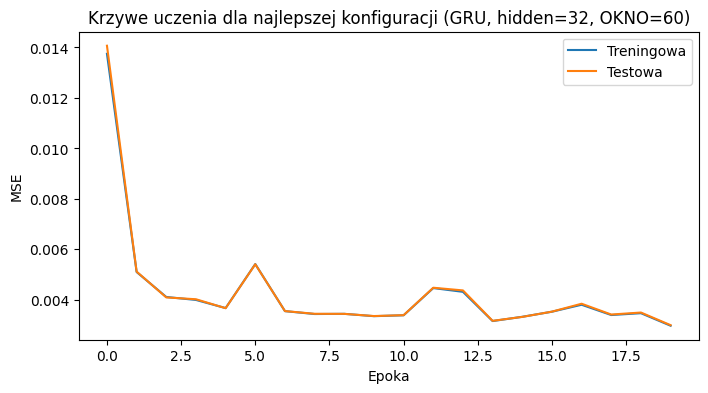

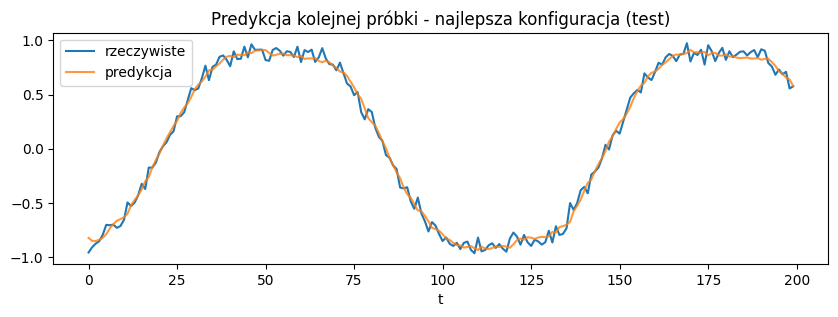

In [13]:
import matplotlib.pyplot as plt
import torch

o = 60
hs = 32
typ_komorki = 'GRU'

X, Y = zrob_okna(seria, o)
n_tr = int(0.8*len(X))
Xtr = torch.tensor(X[:n_tr]).to(DEVICE)
Ytr = torch.tensor(Y[:n_tr]).to(DEVICE)
Xte = torch.tensor(X[n_tr:]).to(DEVICE)
Yte = torch.tensor(Y[n_tr:]).to(DEVICE)

torch.manual_seed(0)
model = ModelRNN(hidden=hs, typ=typ_komorki)

h, h_tr = trenuj(model, Xtr, Ytr, Xte, Yte, epoki=20, lr=1e-2, batch=64)

plt.figure(figsize=(8,4))
plt.plot(h_tr, label='Treningowa')
plt.plot(h, label='Testowa')
plt.title('Krzywe uczenia dla najlepszej konfiguracji (GRU, hidden=32, OKNO=60)')
plt.xlabel('Epoka')
plt.ylabel('MSE')
plt.legend()
plt.show()

model.eval()
with torch.no_grad():
    pred = model(Xte).cpu().numpy().ravel()
prawdziwe = Yte.cpu().numpy().ravel()

plt.figure(figsize=(10,3))
plt.plot(prawdziwe[:200], label='rzeczywiste')
plt.plot(pred[:200], label='predykcja', alpha=0.8)
plt.title('Predykcja kolejnej próbki - najlepsza konfiguracja (test)')
plt.xlabel('t')
plt.legend()
plt.show()

## Zadanie na sprawozdanie

1. Zbadaj wpływ **liczby jednostek ukrytych** i **długości okna** (`OKNO`) na jakość predykcji.
2. Dla co najmniej trzech konfiguracji podaj test MSE w tabeli i dołącz krzywe uczenia.
3. Porównaj SimpleRNN, LSTM i GRU — który uczy się szybciej/stabilniej?
4. Wnioski: kiedy większy model/okno pomaga, a kiedy nie?

Format sprawozdania: `00_materialy_wspolne/szablon_sprawozdania.md`.